# Dataset Overview

This project uses the [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). The CSV file is read from a public IBM GitHub copy of the dataset, so no records are generated.

Each row represents one customer. The dataset contains 7,043 rows and 21 columns. The target column is `Churn`. The `customerID` column identifies each customer and will be excluded from model training.

In [1]:
import pandas as pd

file_path = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
customers = pd.read_csv(file_path)

print("Dataset shape (rows, columns):", customers.shape)
print("Column names:")
print(customers.columns.tolist())

Dataset shape (rows, columns): (7043, 21)
Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [2]:
print("Missing values in each column:")
print(customers.isnull().sum())

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [3]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
total_charges_numeric = pd.to_numeric(
    customers["TotalCharges"],
    errors="coerce"
)

invalid_count = total_charges_numeric.isnull().sum()

print("TotalCharges values that cannot be converted:", invalid_count)

TotalCharges values that cannot be converted: 11


In [5]:
customers.loc[
    total_charges_numeric.isnull(),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [6]:
customers["TotalCharges"] = pd.to_numeric(
    customers["TotalCharges"],
    errors="coerce"
)

customers["TotalCharges"] = customers["TotalCharges"].fillna(0)

print("Missing TotalCharges values:", customers["TotalCharges"].isnull().sum())
print("TotalCharges data type:", customers["TotalCharges"].dtype)

Missing TotalCharges values: 0
TotalCharges data type: float64


In [7]:
customers.loc[
    total_charges_numeric.isnull(),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


In [8]:
print(customers["Churn"].value_counts())
print(customers["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


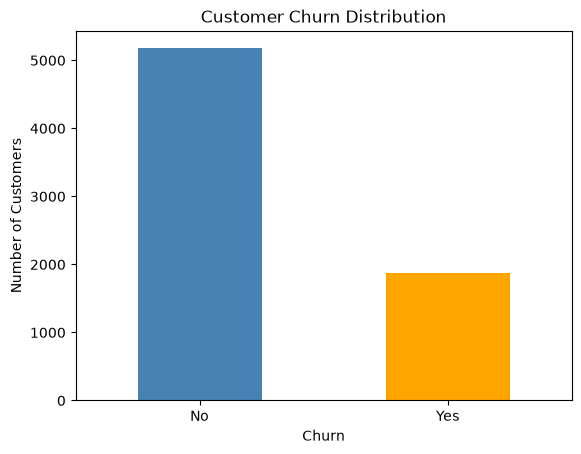

In [9]:
import matplotlib.pyplot as plt

churn_counts = customers["Churn"].value_counts().reindex(["No", "Yes"])

churn_counts.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

Most customers stayed with the company. The target classes are imbalanced: 73.5% stayed and 26.5% churned.

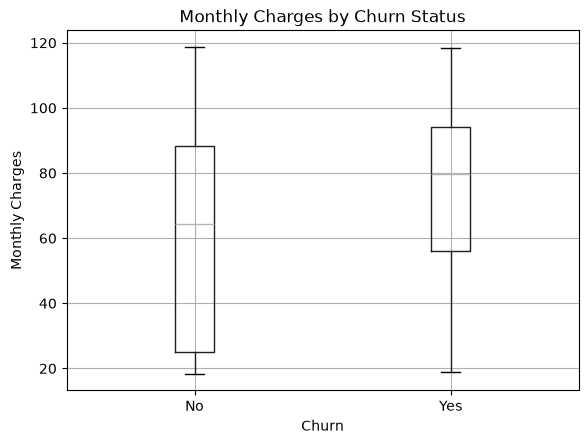

In [10]:
customers.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

Customers who churned had a higher median monthly charge than customers who stayed. However, the two groups overlap, so monthly charges alone do not explain churn.

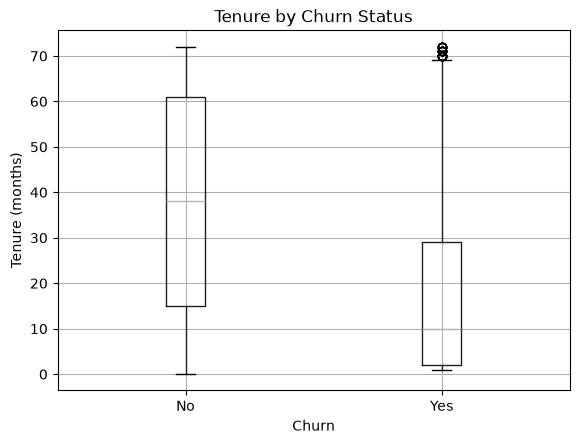

In [11]:
customers.boxplot(column="tenure", by="Churn")
plt.title("Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

Customers who churned generally had a shorter tenure than customers who stayed. This suggests that newer customers may be more likely to churn.

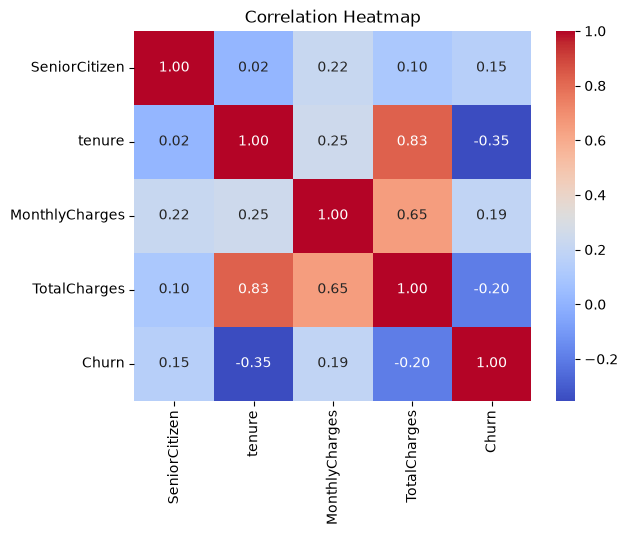

In [12]:
import seaborn as sns

correlation_data = customers[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].copy()

correlation_data["Churn"] = customers["Churn"].map({"No": 0, "Yes": 1})

sns.heatmap(correlation_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

Tenure has the strongest relationship with churn in this heatmap (-0.35). Longer-tenure customers tend to churn less. Correlation does not prove causation.

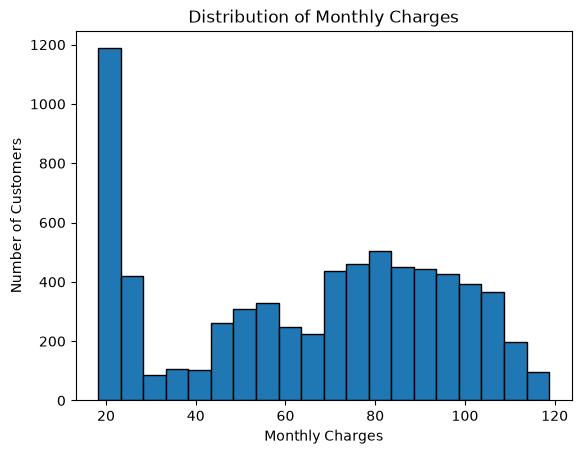

In [13]:
customers["MonthlyCharges"].plot(
    kind="hist",
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

Monthly charges are concentrated around 20 and across a broader range from about 70 to 100.

In [14]:
X = customers.drop(columns=["Churn", "customerID"])
y = customers["Churn"].map({"No": 0, "Yes": 1})

print("Feature data shape:", X.shape)
print("Target values:")
print(y.value_counts())

Feature data shape: (7043, 19)
Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)
print("Churn rate in training set:", y_train.mean().round(3))
print("Churn rate in test set:", y_test.mean().round(3))

Training set: (5634, 19) (5634,)
Test set: (1409, 19) (1409,)
Churn rate in training set: 0.265
Churn rate in test set: 0.265


In [16]:
print(X_train.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_columns = X_train.select_dtypes(include="object").columns
numeric_columns = X_train.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numbers", StandardScaler(), numeric_columns)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training data:", X_train_prepared.shape)
print("Prepared test data:", X_test_prepared.shape)

Prepared training data: (5634, 45)
Prepared test data: (1409, 45)


### Feature Engineering Decision

No additional features were created. `Contract` already contains useful contract categories. An average-spend feature based on `TotalCharges / tenure` would be similar to `MonthlyCharges` and would require special handling for customers with zero tenure.

In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_prepared, y_train)

print("Baseline model trained.")

Baseline model trained.


In [19]:
logistic_predictions = logistic_model.predict(X_test_prepared)

print("First 10 predictions:", logistic_predictions[:10])
print("First 10 actual values:", y_test.iloc[:10].tolist())

First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 actual values: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 3))
print("Precision:", round(precision_score(y_test, logistic_predictions, pos_label=1), 3))
print("Recall:", round(recall_score(y_test, logistic_predictions, pos_label=1), 3))
print("F1 score:", round(f1_score(y_test, logistic_predictions, pos_label=1), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, logistic_predictions, labels=[0, 1]))

Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1 score: 0.604
Confusion matrix:
[[926 109]
 [165 209]]


### Logistic Regression Baseline

On the test set, Logistic Regression achieved an accuracy of 0.806, precision of 0.657, recall of 0.559, and an F1 score of 0.604. The confusion matrix was 
[[926, 109], [165, 209]]. With churn treated as the positive class, the model identified 209 of 374 churn customers and missed 165.

In [21]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_prepared, y_train)

print("Decision Tree model trained.")

Decision Tree model trained.


In [22]:
tree_predictions = tree_model.predict(X_test_prepared)

print("First 10 predictions:", tree_predictions[:10])
print("First 10 actual values:", y_test.iloc[:10].tolist())

First 10 predictions: [0 1 0 1 0 0 0 0 0 1]
First 10 actual values: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]


In [23]:
print("Accuracy:", round(accuracy_score(y_test, tree_predictions), 3))
print("Precision:", round(precision_score(y_test, tree_predictions, pos_label=1), 3))
print("Recall:", round(recall_score(y_test, tree_predictions, pos_label=1), 3))
print("F1 score:", round(f1_score(y_test, tree_predictions, pos_label=1), 3))
print("Confusion matrix:")
print(confusion_matrix(y_test, tree_predictions, labels=[0, 1]))

Accuracy: 0.722
Precision: 0.478
Recall: 0.497
F1 score: 0.488
Confusion matrix:
[[832 203]
 [188 186]]


### Decision Tree Results

On the test set, Decision Tree achieved an accuracy of 0.722, precision of 0.478, recall of 0.497, and an F1 score of 0.488. Its confusion matrix was [[832, 203], [188, 186]]. It performed worse than the Logistic Regression baseline on these metrics.